# 92장 · 기준선 측정·1차 점검 · 방향과 예시

91장의 최소 경로로 고정 질문 일곱 개를 실행한 기록이 있습니다. 화면에 답이 떴더라도 문서에 없는 질문에 엉뚱한 규정을 인용했다면 실패로 남겨야 합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 팀별 변형을 시도한 뒤 해당 셀 아래에서 예시를 펼쳐 비교할 수 있습니다.

## 같은 판본의 기록만 세기

기준선 카드　프로젝트 PROJECT-EQUIPMENT-01 / 문서 rules-v1 / 질문 eval-v1 / 로컬 규칙 thin / 일곱 문항 중 두 문항 통과. 여기에 모델이 개입한 적은 없습니다. 다음 변경을 비교할 때는 질문·원문을 그대로 쓰고 무엇을 바꿨는지 한 줄로 남깁니다.


### 셀 01 · 저장된 실행 기록으로 통과 수 세기

baseline.json에서 질문 번호와 통과 여부만 꺼낸 자료입니다. 빈칸을 잘된 것으로 세지 않도록 실제 True인 행만 셉니다.

In [1]:
records = [{'id': 'Q01', 'passed': False},
 {'id': 'Q02', 'passed': True},
 {'id': 'Q03', 'passed': False},
 {'id': 'Q04', 'passed': False},
 {'id': 'Q05', 'passed': False},
 {'id': 'Q06', 'passed': True},
 {'id': 'Q07', 'passed': False}]
print(sum(row["passed"] is True for row in records), "/", len(records))

2 / 7


2 / 7이 나옵니다. 같은 일곱 질문을 보며 코드를 수정하므로 이 비율은 공개 개발 사례의 결과입니다. 다른 사용자 질문에 대한 정확도로 발표할 수 없습니다.

## Q03의 기대와 실제가 갈라진 지점

실패 기록 예시　Q03 / 기대 no_evidence, 인용 없음 / 실제 answered, RULE-A 인용 / 원인 장비명만 일치하면 점검 문장을 반환 / 수정 후보 일정 문의를 답변 불가로 처리. 반면 Q01은 답의 의미가 맞아도 출처에 절과 개정일이 빠졌습니다. 서로 다른 두 문제를 ‘답변 품질 개선’ 한 줄에 뭉치면 수정 순서를 정하기 어렵습니다.

<!-- motion:baseline-error -->
**7문항 중 두 개를 맞힌 기록에서 어디를 고칠까요?**

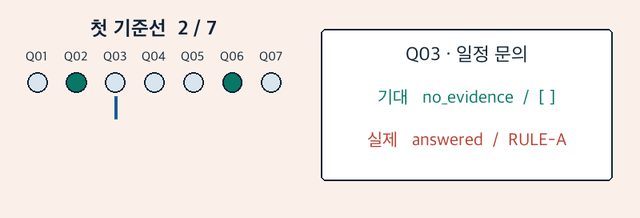

Q03의 기대는 no_evidence와 빈 출처입니다. 첫 구현은 장비명만 보고 answered와 RULE-A를 반환했습니다. 전체 점수에서 이 한 행을 꺼내야 오류가 보입니다.
<!-- /motion -->


### 과제 02 · 선택 연습 · Q01의 실패 항목 찾기

기록된 검사 결과에서 실패한 항목의 이름을 뽑아 설계 담당자에게 전하세요.

Q01에서 답과 문서 ID가 맞아도 절 정보가 빠지면 source_metadata는 False입니다. 모든 필수 조건을 만족해야 하는 전체 passed도 False가 됩니다. 셀 01의 2/7은 이렇게 판정해 둔 일곱 행을 집계한 값입니다.

In [2]:
checks = {'status': True,
 'source_ids': True,
 'required_facts': True,
 'source_metadata': False,
 'allowed_sources': True,
 'execution_mode': True}
# 값이 False인 항목의 이름을 골라 출력하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>checks = {&#x27;status&#x27;: True,
 &#x27;source_ids&#x27;: True,
 &#x27;required_facts&#x27;: True,
 &#x27;source_metadata&#x27;: False,
 &#x27;allowed_sources&#x27;: True,
 &#x27;execution_mode&#x27;: True}
print([name for name, passed in checks.items() if not passed])</code></pre>
<p>실행 결과</p><pre><code>[&#x27;source_metadata&#x27;]</code></pre>
<p>source_metadata 한 항목이 남습니다. 출처 ID는 이미 맞았으므로 새 검색기를 도입하기에 앞서 응답에 담는 필드를 확인합니다.</p>
</details>

## 돌아보기

개발용 eval-v1에서 2/7이었던 기준선, Q01의 출처 위치 누락, Q03의 질문 의도 오류를 93장 설계 회의에 넘기세요. 모델 호출은 0회였고 운영 비용과 지연은 측정하지 않았습니다.